# Module 3 – Fraud Detection

**Business question:** NovaFin processes thousands of transactions a day. Which ones look suspicious enough to investigate, without wasting the team's time on genuine ones?

This notebook goes through the module in 4 steps:

1. **Exploratory Data Analysis (EDA)** – understand the data and where fraud happens ← *this section*
2. Supervised fraud model – learn from past fraud labels
3. Unsupervised detection – Isolation Forest, without labels
4. Cost-based threshold – choose the cut-off that costs NovaFin the least

---
# Step 1 – Exploratory Data Analysis

Before building any model we look at the data: how much fraud there is, and which kinds of transactions carry more of it. This tells us which columns are likely to be useful for the model, and gives us business findings for the report.

### 1.1 Import libraries

- **pandas** – works with tables of data (like Excel in Python)
- **numpy** – maths on numbers and arrays
- **matplotlib / seaborn** – charts
- **pathlib** – builds file paths that work on any computer

We also create a `results/` folder path so every chart we make is saved there for the report.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

DATA_PATH = Path("../../resources/data/nova_transactions.csv")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

### 1.2 Load the data

`read_csv` loads the file into a table called a **DataFrame** (we name it `df`).
`parse_dates=["Timestamp"]` tells pandas that the Timestamp column is a date/time, not plain text, so we can later extract the hour or the day.

`df.shape` gives (rows, columns), and `df.head()` shows the first 5 rows.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["Timestamp"])
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (30000, 12)


,Transaction_ID,Customer_ID,Timestamp,Amount,Transaction_Type,Merchant_Category,Location,Device_ID,Account_Age_Months,Historical_Avg_Transaction,Transaction_Frequency,Fraud_Flag
0,5000001,200541,2025-01-01 00:00:00.000000000,2582.90,Payment,Retail,Chennai,11437,77,4650.19,8,0
1,5000002,201166,2025-01-01 00:29:08.218273942,1236.10,Payment,Travel,Pune,10504,170,9832.22,10,0
2,5000003,200479,2025-01-01 00:58:16.436547884,7909.31,Transfer,Investment,Hyderabad,11361,67,5655.09,8,0
3,5000004,201405,2025-01-01 01:27:24.654821827,41417.90,Transfer,Retail,Mumbai,10944,133,8045.82,9,0
4,5000005,202330,2025-01-01 01:56:32.873095769,10893.53,Withdrawal,Utilities,Kolkata,11100,62,13553.16,5,0


### 1.3 Data quality check

Before analysing, we check three things:
- **Data types** – is each column a number, text or date as expected?
- **Missing values** – empty cells would need to be filled or removed
- **Duplicate rows** – the same transaction recorded twice would distort results

In [3]:
print(df.dtypes, "\n")
print("Missing values per column:")
print(df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Transaction_IDs:", df["Transaction_ID"].duplicated().sum())

Transaction_ID                         int64
Customer_ID                            int64
Timestamp                     datetime64[ns]
Amount                               float64
Transaction_Type                      object
Merchant_Category                     object
Location                              object
Device_ID                              int64
Account_Age_Months                     int64
Historical_Avg_Transaction           float64
Transaction_Frequency                  int64
Fraud_Flag                             int64
dtype: object 

Missing values per column:
Transaction_ID                0
Customer_ID                   0
Timestamp                     0
Amount                        0
Transaction_Type              0
Merchant_Category             0
Location                      0
Device_ID                     0
Account_Age_Months            0
Historical_Avg_Transaction    0
Transaction_Frequency         0
Fraud_Flag                    0
dtype: int64 

Duplicate rows: 0


**Result:** all columns have the expected types, there are no missing values and no duplicates. The data is clean, so no cleaning step is needed.

### 1.4 Summary statistics

`describe()` gives the count, mean, standard deviation, min, quartiles and max for every numeric column. It is a quick way to spot strange values (negative amounts, impossible ages) and skewed columns.

In [4]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Transaction_ID,30000.0,5015000.5,5000001.0,5007500.75,5015000.5,5022500.25,5030000.0,8660.398374
Customer_ID,30000.0,201253.0897,200001.0,200628.0,201255.0,201874.0,202500.0,719.947328
Timestamp,30000,2025-10-31 11:59:59.999999744,2025-01-01 00:00:00,2025-06-01 18:00:00,2025-10-31 12:00:00,2026-04-01 06:00:00,2026-08-31 00:00:00,NaN
Amount,30000.0,10761.193476,147.96,3338.795,6539.635,12783.8925,434340.19,14245.084436
Device_ID,30000.0,10749.5002,10000.0,10378.0,10744.0,11126.0,11499.0,432.946197
Account_Age_Months,30000.0,91.000667,3.0,47.0,91.0,135.0,179.0,50.883804
Historical_Avg_Transaction,30000.0,6995.244357,355.22,3403.11,5489.855,8775.3425,80161.54,5519.063842
Transaction_Frequency,30000.0,9.006233,1.0,7.0,9.0,11.0,27.0,2.832407
Fraud_Flag,30000.0,0.0228,0.0,0.0,0.0,0.0,1.0,0.149268


**What to notice:**
- `Amount` has a median of about ₹6,500 but a maximum of ₹4.3 lakh – a few very large transactions. The data is **right-skewed** (a long tail of big values), so we will use a log scale for amount charts.
- `Transaction_ID`, `Customer_ID` and `Device_ID` are numbers, but they are **labels**, not quantities. Their average means nothing, and we will not feed them to the model as numbers.
- `Fraud_Flag` has a mean of about 0.023 – that is the fraud rate (next cell).

### 1.5 Fraud rate – how imbalanced is the data?

`Fraud_Flag` is 1 for fraud and 0 for genuine. Counting each value tells us how rare fraud is.

This is the most important fact for the whole module: if fraud is very rare, **accuracy is a misleading metric**. A model that predicts "never fraud" would be right almost every time and still catch nothing.

Fraud_Flag
0    29316
1      684
Name: count, dtype: int64

Fraud rate: 2.28%
Accuracy of a model that always says 'not fraud': 97.72%


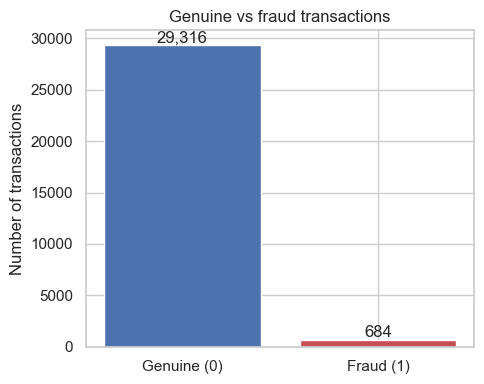

In [5]:
counts = df["Fraud_Flag"].value_counts().sort_index()
fraud_rate = df["Fraud_Flag"].mean()
print(counts)
print(f"\nFraud rate: {fraud_rate:.2%}")
print(f"Accuracy of a model that always says 'not fraud': {1 - fraud_rate:.2%}")

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Genuine (0)", "Fraud (1)"], counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Genuine vs fraud transactions")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.savefig(RESULTS / "eda_01_fraud_rate.png", dpi=150)
plt.show()

**Result:** only **684 of 30,000 transactions (2.28%) are fraud**. The data is highly **imbalanced**.

**What this means for modelling:**
- We will judge models by **recall** (share of fraud caught), **precision** (share of flagged transactions that really are fraud) and **PR-AUC**, not accuracy.
- When we split data into training and test sets we will use a **stratified** split, so both sets keep the same 2.28% fraud rate.

### 1.6 Fraud by category – a reusable helper

We want to see the fraud rate for each transaction type, merchant category and city. Instead of writing the same code three times, we write one small **function** and call it for each column.

For a given column the function:
1. groups transactions by each value (e.g. Payment, Transfer, Withdrawal),
2. calculates the number of transactions, number of frauds and fraud rate,
3. draws a bar chart with a dashed line at the overall 2.28% rate, so we can see which groups are above or below average.

In [6]:
def fraud_rate_by(col, filename):
    table = (df.groupby(col)["Fraud_Flag"]
               .agg(transactions="count", frauds="sum", fraud_rate="mean")
               .sort_values("fraud_rate", ascending=False))

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(table.index.astype(str), table["fraud_rate"] * 100, color="#C44E52")
    ax.axhline(fraud_rate * 100, color="black", linestyle="--",
               label=f"Overall {fraud_rate:.2%}")
    ax.set_title(f"Fraud rate by {col}")
    ax.set_ylabel("Fraud rate (%)")
    ax.legend()
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(RESULTS / filename, dpi=150)
    plt.show()

    table["fraud_rate"] = (table["fraud_rate"] * 100).round(2).astype(str) + "%"
    return table

#### Fraud by transaction type

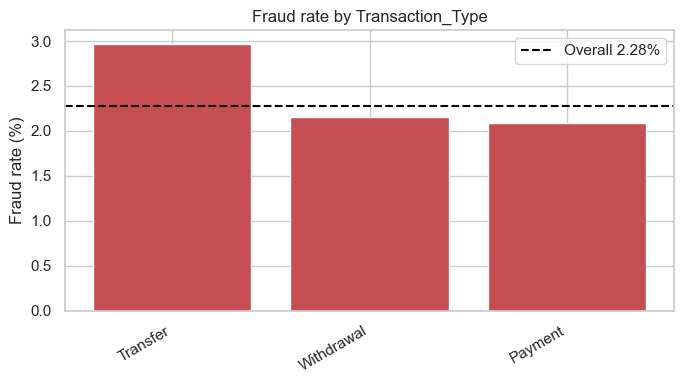

,transactions,frauds,fraud_rate
Transaction_Type,,,
Transfer,5961,177,2.97%
Withdrawal,7524,162,2.15%
Payment,16515,345,2.09%


In [7]:
fraud_rate_by("Transaction_Type", "eda_02_fraud_by_type.png")

**Result:** **Transfers** have the highest fraud rate (~2.97%), about 40% higher than Payments (~2.09%) and Withdrawals (~2.15%). This makes sense: a fraudster who takes over an account usually wants to move money out quickly, and a transfer does that.

Note that Payments still have the **most fraud cases** (345) simply because there are many more payments. Rate and count tell different stories – both matter to the business.

#### Fraud by merchant category

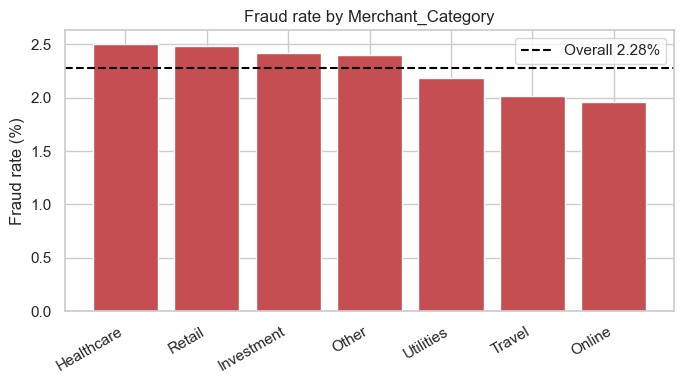

,transactions,frauds,fraud_rate
Merchant_Category,,,
Healthcare,4315,108,2.5%
Retail,4309,107,2.48%
Investment,4261,103,2.42%
Other,4337,104,2.4%
Utilities,4257,93,2.18%
Travel,4178,84,2.01%
Online,4343,85,1.96%


In [8]:
fraud_rate_by("Merchant_Category", "eda_03_fraud_by_merchant.png")

**Result:** fraud rates range only from ~1.96% (Online) to ~2.50% (Healthcare). All categories are close to the 2.28% average, so **merchant category on its own is a weak signal** of fraud.

#### Fraud by location

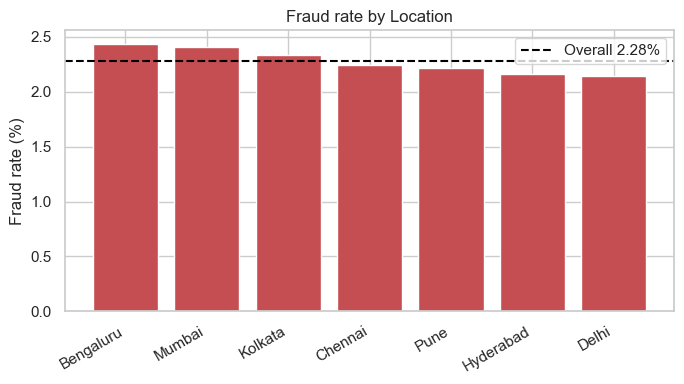

,transactions,frauds,fraud_rate
Location,,,
Bengaluru,4307,105,2.44%
Mumbai,4282,103,2.41%
Kolkata,4233,99,2.34%
Chennai,4278,96,2.24%
Pune,4368,97,2.22%
Hyderabad,4292,93,2.17%
Delhi,4240,91,2.15%


In [9]:
fraud_rate_by("Location", "eda_04_fraud_by_location.png")

**Result:** fraud rates by city range from ~2.15% (Delhi) to ~2.44% (Bengaluru). The differences are small and could easily be random. **Location on its own is also a weak signal.**

So far, the *kind* of transaction tells us little. Next we look at the *size* of the transaction.

### 1.7 Fraud by amount

Two views:
1. A **box plot** comparing amounts of genuine and fraud transactions. The box shows the middle 50% of values and the line inside is the median. We use a **log scale** because amounts are very skewed.
2. **Fraud rate by amount band.** `pd.qcut(..., 5)` splits transactions into 5 equal-sized groups (quintiles), from the smallest 20% to the largest 20%.

Median amount (₹):
Fraud_Flag
Genuine     6411.0
Fraud      26438.0
Name: Amount, dtype: float64


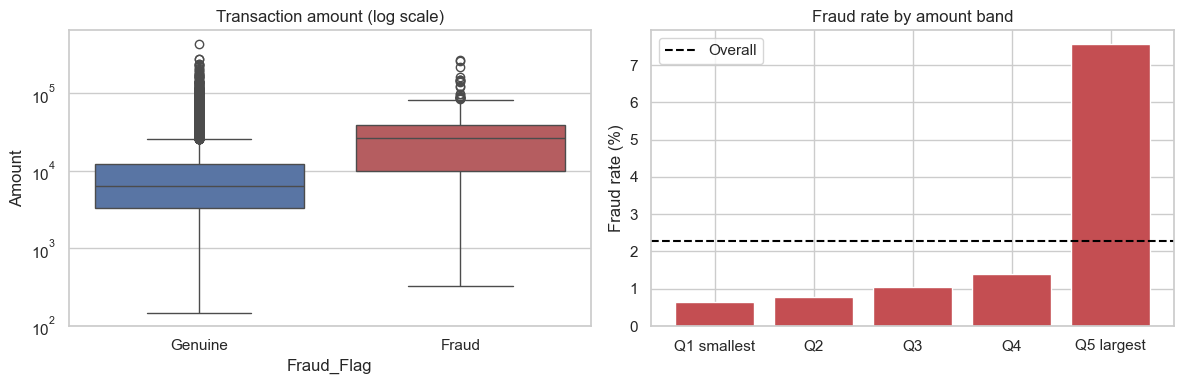

Amount_Band
Q1 smallest    0.63
Q2             0.78
Q3             1.05
Q4             1.38
Q5 largest     7.55
Name: Fraud_Flag, dtype: float64

In [10]:
print("Median amount (₹):")
print(df.groupby("Fraud_Flag")["Amount"].median().rename({0: "Genuine", 1: "Fraud"}).round(0))

df["Amount_Band"] = pd.qcut(df["Amount"], 5,
                            labels=["Q1 smallest", "Q2", "Q3", "Q4", "Q5 largest"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Fraud_Flag", y="Amount", ax=axes[0], palette=["#4C72B0", "#C44E52"],
            hue="Fraud_Flag", legend=False)
axes[0].set_yscale("log")
axes[0].set_xticks([0, 1], ["Genuine", "Fraud"])
axes[0].set_title("Transaction amount (log scale)")

band_rate = df.groupby("Amount_Band", observed=True)["Fraud_Flag"].mean() * 100
axes[1].bar(band_rate.index.astype(str), band_rate.values, color="#C44E52")
axes[1].axhline(fraud_rate * 100, color="black", linestyle="--", label="Overall")
axes[1].set_title("Fraud rate by amount band")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS / "eda_05_fraud_by_amount.png", dpi=150)
plt.show()

band_rate.round(2)

**Result:** amount is a **strong signal**.
- The median fraud transaction is about **₹26,400**, roughly **4× the median genuine transaction** (~₹6,400).
- In the largest 20% of transactions the fraud rate is about **7.6%**, more than 3× the average. In the smallest 20% it is only about 0.6%.

Business meaning: fraudsters try to take as much as possible, so large transactions deserve more attention.

### 1.8 Fraud by customer behaviour

A ₹30,000 transfer is normal for one customer and very unusual for another. What matters is often not the amount itself, but **how different it is from what this customer usually does**.

We create a new column (this is called **feature engineering**):

**`Amount_to_Avg_Ratio` = Amount ÷ Historical_Avg_Transaction**

- A ratio of 1 means the customer spent their usual amount.
- A ratio of 5 means they spent 5× their usual amount – suspicious.

We also look at **account age** (new accounts are often opened for fraud) and **transaction frequency**.

In [11]:
df["Amount_to_Avg_Ratio"] = df["Amount"] / df["Historical_Avg_Transaction"]

behaviour_cols = ["Amount_to_Avg_Ratio", "Historical_Avg_Transaction",
                  "Account_Age_Months", "Transaction_Frequency"]
print("Median values, genuine vs fraud:")
df.groupby("Fraud_Flag")[behaviour_cols].median().rename(index={0: "Genuine", 1: "Fraud"}).round(2)

Median values, genuine vs fraud:


,Amount_to_Avg_Ratio,Historical_Avg_Transaction,Account_Age_Months,Transaction_Frequency
Fraud_Flag,,,,
Genuine,1.17,5524.34,90.0,9.0
Fraud,5.00,4507.31,93.0,9.0


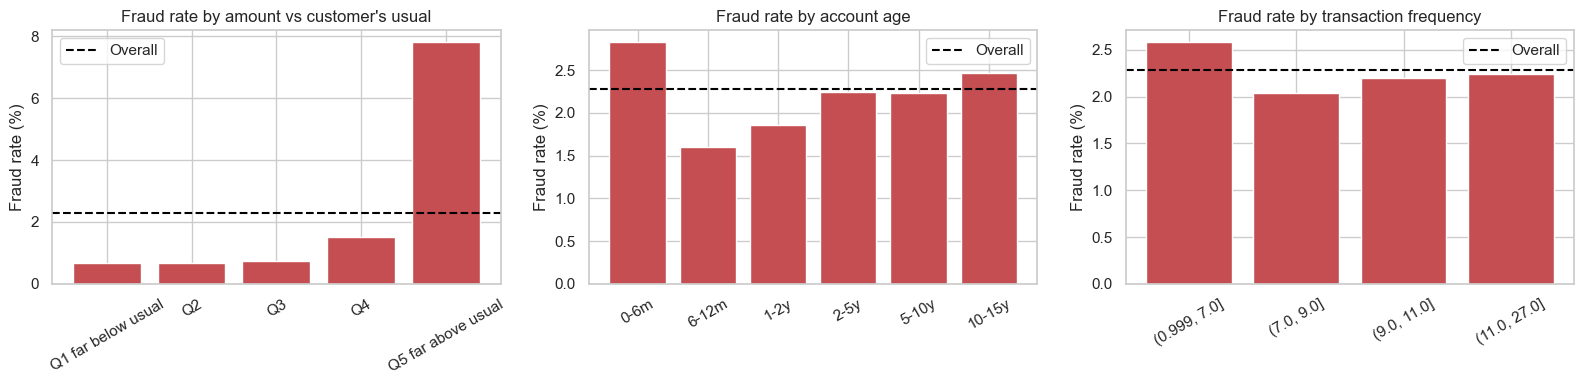

Transactions above 3x the customer's usual amount: 22.4% of all transactions
  ... fraud rate in this group: 7.44%
  ... share of ALL fraud found in this group: 73.2%


In [12]:
df["Ratio_Band"] = pd.qcut(df["Amount_to_Avg_Ratio"], 5,
                           labels=["Q1 far below usual", "Q2", "Q3", "Q4", "Q5 far above usual"])
df["Account_Age_Band"] = pd.cut(df["Account_Age_Months"], [0, 6, 12, 24, 60, 120, 180],
                                labels=["0-6m", "6-12m", "1-2y", "2-5y", "5-10y", "10-15y"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in [
    (axes[0], "Ratio_Band", "Fraud rate by amount vs customer's usual"),
    (axes[1], "Account_Age_Band", "Fraud rate by account age"),
    (axes[2], "Transaction_Frequency", "Fraud rate by transaction frequency"),
]:
    if col == "Transaction_Frequency":
        groups = pd.qcut(df[col], 4, duplicates="drop")
        rate = df.groupby(groups, observed=True)["Fraud_Flag"].mean() * 100
    else:
        rate = df.groupby(col, observed=True)["Fraud_Flag"].mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color="#C44E52")
    ax.axhline(fraud_rate * 100, color="black", linestyle="--", label="Overall")
    ax.set_title(title)
    ax.set_ylabel("Fraud rate (%)")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "eda_06_fraud_by_behaviour.png", dpi=150)
plt.show()

big_jump = df["Amount_to_Avg_Ratio"] > 3
print(f"Transactions above 3x the customer's usual amount: {big_jump.mean():.1%} of all transactions")
print(f"  ... fraud rate in this group: {df.loc[big_jump, 'Fraud_Flag'].mean():.2%}")
print(f"  ... share of ALL fraud found in this group: {df.loc[big_jump, 'Fraud_Flag'].sum() / df['Fraud_Flag'].sum():.1%}")

**Result:**
- **Amount vs usual spending is the strongest signal so far.** The median fraud transaction is **5× the customer's usual amount**, against about 1.2× for genuine ones.
- Transactions above 3× the usual amount are about 22% of all transactions, but they contain about **73% of all fraud**. A simple rule like "check anything over 3× usual" would already catch most fraud, but it would also flag thousands of genuine transactions. The model's job is to do better than this rule.
- **Account age:** the newest accounts (0–6 months) have the highest fraud rate (~2.8%), but the pattern across older accounts is weak.
- **Transaction frequency:** customers who transact least often (7 or fewer) are slightly higher (~2.6%); otherwise rates are close to average, so frequency is a weak signal on its own.

### 1.9 Fraud by time of day

The Timestamp lets us check whether fraud is more common at certain hours (for example at night, when customers are asleep and less likely to notice). `.dt.hour` extracts the hour (0–23).

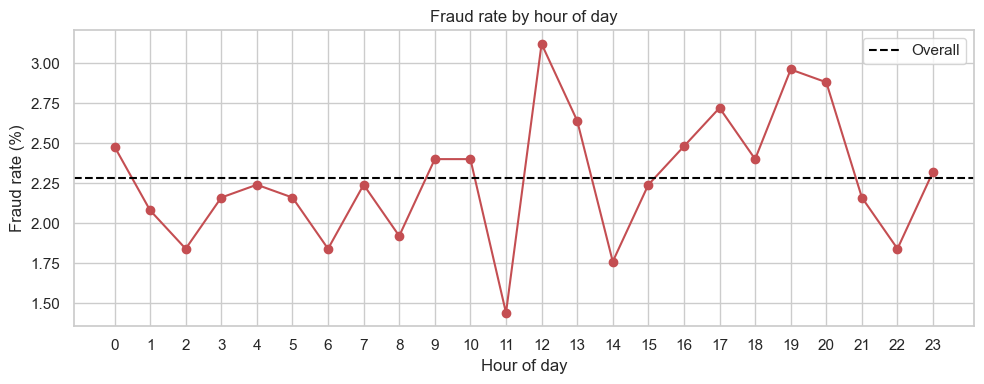

Data covers: 2025-01-01 to 2026-08-31


In [13]:
df["Hour"] = df["Timestamp"].dt.hour
hour_rate = df.groupby("Hour")["Fraud_Flag"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hour_rate.index, hour_rate.values, marker="o", color="#C44E52")
ax.axhline(fraud_rate * 100, color="black", linestyle="--", label="Overall")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate by hour of day")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "eda_07_fraud_by_hour.png", dpi=150)
plt.show()

print("Data covers:", df["Timestamp"].min().date(), "to", df["Timestamp"].max().date())

**Result:** the fraud rate moves between about 1.4% and 3.1% from hour to hour, with no clear night-time pattern (with only ~1,250 transactions per hour, much of this is random noise). **Time of day is a weak signal** in this data.

The data covers January 2025 to August 2026. That matters later: to test the model fairly, we could train on earlier months and test on later months, the way it would be used in real life.

### 1.10 Correlation with fraud

**Correlation** measures how strongly two numeric columns move together, from -1 to +1. 0 means no linear relationship. We check each numeric column's correlation with `Fraud_Flag`.

Correlation only finds straight-line relationships, so it is a rough guide, not the final word.

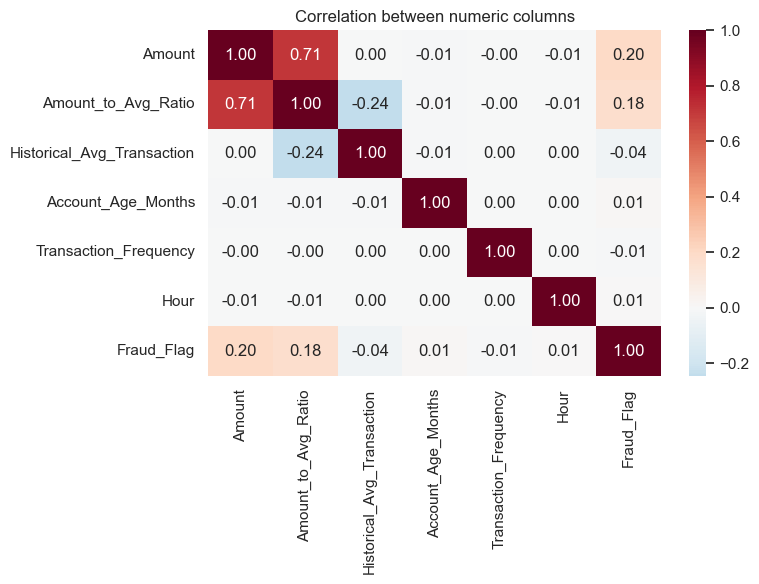

Amount                        0.200
Amount_to_Avg_Ratio           0.177
Account_Age_Months            0.010
Hour                          0.007
Transaction_Frequency        -0.008
Historical_Avg_Transaction   -0.038
Name: Fraud_Flag, dtype: float64

In [14]:
num_cols = ["Amount", "Amount_to_Avg_Ratio", "Historical_Avg_Transaction",
            "Account_Age_Months", "Transaction_Frequency", "Hour", "Fraud_Flag"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlation between numeric columns")
plt.tight_layout()
plt.savefig(RESULTS / "eda_08_correlation.png", dpi=150)
plt.show()

corr["Fraud_Flag"].drop("Fraud_Flag").sort_values(ascending=False).round(3)

**Result:** `Amount` (~0.20) and `Amount_to_Avg_Ratio` (~0.18) are the only columns with a clear relationship to fraud. All others are close to 0. This confirms the charts above.

### 1.11 Columns we will not use as model features

| Column | Why not |
|---|---|
| `Transaction_ID` | A unique row number – it carries no information about fraud |
| `Customer_ID` | An identifier. Using it would let the model memorise customers instead of learning patterns, and it would not work for new customers |
| `Device_ID` | Also an identifier. Each device is shared by about 20 different customers in this data, so it does not behave like a real personal device |
| `Timestamp` | We keep the useful part (`Hour`) instead of the raw date |

We check the Device_ID claim below.

In [15]:
customers_per_device = df.groupby("Device_ID")["Customer_ID"].nunique()
print("Unique customers:", df["Customer_ID"].nunique())
print("Unique devices:  ", df["Device_ID"].nunique())
print("Customers per device – average:", round(customers_per_device.mean(), 1),
      " min:", customers_per_device.min(), " max:", customers_per_device.max())

Unique customers: 2500
Unique devices:   1500
Customers per device – average: 19.9  min: 5  max: 37


### 1.12 Summary of Step 1

**Data:** 30,000 clean transactions (Jan 2025 – Aug 2026), no missing values, **2.28% fraud**.

**Key findings**

| Factor | Signal strength | Finding |
|---|---|---|
| Amount vs customer's usual | **Strong** | Fraud is typically ~5× the customer's usual amount; transactions above 3× usual hold ~73% of all fraud |
| Amount | **Strong** | Median fraud ~₹26,400 vs ~₹6,400 genuine; top 20% of amounts have ~7.6% fraud rate |
| Transaction type | Moderate | Transfers ~2.97% vs ~2.1% for payments and withdrawals |
| Account age | Weak | Newest accounts (0–6 months) slightly higher at ~2.8% |
| Merchant, location, frequency, hour | Weak | All close to the 2.28% average |

**What this means for the next steps**
1. Use **precision, recall and PR-AUC**, not accuracy, and a **stratified** train/test split.
2. Keep the engineered feature **`Amount_to_Avg_Ratio`** – it captures "unusual for this customer".
3. Use log of amount, because amounts are very skewed.
4. Drop the ID columns.

**Business message:** fraud at NovaFin is mainly about **unusually large transactions compared with the customer's normal behaviour**, especially transfers. *Where* or *what* the transaction is for matters much less.

---
# Step 2 – Supervised Fraud Model

**Supervised** means the model learns from examples where we already know the answer (`Fraud_Flag`). It looks at thousands of past transactions, learns which patterns go with fraud, and then gives each new transaction a **fraud probability** between 0 and 1.

What we will do:
1. Prepare the features (the input columns)
2. Split the data into a training set and a test set
3. Build a simple rule as a baseline to beat
4. Train three models and compare them fairly
5. Check which features drive the predictions
6. Pick a model for Steps 3 and 4

### 2.1 Import the modelling tools

All of these come from **scikit-learn** (`sklearn`), the standard Python ML library.

| Tool | What it does |
|---|---|
| `train_test_split` | Splits data into training and test sets |
| `StratifiedKFold`, `cross_validate` | Cross-validation (explained in 2.6) |
| `ColumnTransformer`, `OneHotEncoder`, `StandardScaler` | Prepare columns for the model |
| `Pipeline` | Chains preparation + model into one object |
| `LogisticRegression`, `RandomForestClassifier`, `HistGradientBoostingClassifier` | The three models |
| `roc_auc_score`, `average_precision_score`, ... | Evaluation metrics |
| `permutation_importance` | Measures which features matter |

In [16]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

### 2.2 Prepare the features

Based on the EDA we use these inputs:

| Feature | Type | Why |
|---|---|---|
| `Log_Amount` | number | Amount was the strongest signal. We take the **log** because amounts are very skewed (₹150 to ₹4.3 lakh); the log squeezes that range so a few huge values don't dominate |
| `Log_Amount_to_Avg` | number | Log of Amount ÷ customer's usual amount – the "unusual for this customer" signal |
| `Account_Age_Months` | number | Newest accounts had slightly more fraud |
| `Transaction_Frequency` | number | Customer activity level |
| `Hour` | number | Time of day |
| `Transaction_Type` | category | Transfers had more fraud |
| `Merchant_Category` | category | Weak signal, but the model can decide |
| `Location` | category | Weak signal, but the model can decide |

**Why not also include `Historical_Avg_Transaction`?** Because log(Amount ÷ Avg) = log(Amount) − log(Avg). Once we have the first two features, the third adds no new information, and giving a model three columns where one is an exact combination of the other two confuses logistic regression.

`X` holds the inputs and `y` holds the answer we want to predict.

In [17]:
df["Log_Amount"] = np.log(df["Amount"])
df["Log_Amount_to_Avg"] = np.log(df["Amount"] / df["Historical_Avg_Transaction"])
df["Hour"] = df["Timestamp"].dt.hour

NUM_FEATURES = ["Log_Amount", "Log_Amount_to_Avg", "Account_Age_Months",
                "Transaction_Frequency", "Hour"]
CAT_FEATURES = ["Transaction_Type", "Merchant_Category", "Location"]

X = df[NUM_FEATURES + CAT_FEATURES]
y = df["Fraud_Flag"]
X.head()

,Log_Amount,Log_Amount_to_Avg,Account_Age_Months,Transaction_Frequency,Hour,Transaction_Type,Merchant_Category,Location
0,7.856668,-0.587995,77,8,0,Payment,Retail,Chennai
1,7.119717,-2.073703,170,10,0,Payment,Travel,Pune
2,8.975796,0.335485,67,8,0,Transfer,Investment,Hyderabad
3,10.631468,1.638560,133,9,1,Transfer,Retail,Mumbai
4,9.295924,-0.218451,62,5,1,Withdrawal,Utilities,Kolkata


### 2.3 Split into training and test sets

We hide 25% of the data as a **test set**. The models never see it while learning. At the end we score them on it, which tells us how well they would work on **new** transactions. Testing on the same data a model learned from would be like giving students the exam questions in advance.

- `test_size=0.25` → 75% training (22,500 rows), 25% test (7,500 rows)
- `stratify=y` → both sets keep the same 2.28% fraud rate. Without this, by bad luck, the test set might get too few fraud cases
- `random_state=42` → the split is the same every time we run the notebook, so results are reproducible

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

print(f"Training set: {len(X_train):,} rows, {y_train.sum()} frauds ({y_train.mean():.2%})")
print(f"Test set:     {len(X_test):,} rows, {y_test.sum()} frauds ({y_test.mean():.2%})")

Training set: 22,500 rows, 513 frauds (2.28%)
Test set:     7,500 rows, 171 frauds (2.28%)


### 2.4 Preparing columns for the model

Models only understand numbers, and some need the numbers on a similar scale. A `ColumnTransformer` applies a different preparation to each kind of column:

- **`StandardScaler`** (numeric columns) rescales each column to average 0 and spread 1. Otherwise logistic regression would treat account age (0–180) as more important than log amount (5–13) just because its numbers are bigger.
- **`OneHotEncoder`** (category columns) turns one text column into several 0/1 columns. `Transaction_Type` becomes `Type_Payment`, `Type_Transfer`, `Type_Withdrawal`, with a 1 in the matching column.

We then put the preparation and the model together in a **`Pipeline`**. This matters for **avoiding data leakage**: the scaler learns its averages from the training data only, never from the test data. If the test data influenced the preparation, the test score would be slightly too optimistic.

In [19]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
])

def make_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

### 2.5 How we will measure the models

With only 2.28% fraud we cannot use accuracy. We use:

| Metric | Plain meaning | Random guess | Perfect |
|---|---|---|---|
| **ROC-AUC** | Pick one fraud and one genuine transaction at random – how often does the model give the fraud the higher score? | 0.50 | 1.00 |
| **PR-AUC** (average precision) | How precise the model's flags are across all possible cut-offs. **The best single metric for rare fraud** | 0.023 (the fraud rate) | 1.00 |
| **Brier score** | Average squared gap between the predicted probability and what happened. Checks whether a "10% fraud probability" really means about 10% | – | 0 (lower is better) |
| **Fraud caught in top 5%** | If investigators can check the 5% most suspicious transactions, what share of all fraud do they find? | 5% | 100% |

The last one is a **business metric**: it doesn't depend on any cut-off and is easy to explain to management.

The helper below calculates all four for a set of predicted probabilities.

In [20]:
def evaluate(y_true, scores, top_share=0.05):
    y_true = np.asarray(y_true)
    n_top = int(len(y_true) * top_share)
    top_idx = np.argsort(-scores)[:n_top]          # indices of the highest scores
    caught = y_true[top_idx].sum()
    return {
        "ROC-AUC": roc_auc_score(y_true, scores),
        "PR-AUC": average_precision_score(y_true, scores),
        "Brier": brier_score_loss(y_true, scores) if scores.max() <= 1 else np.nan,
        "Fraud caught in top 5%": caught / y_true.sum(),
        "Precision in top 5%": caught / n_top,
    }

### 2.6 Baseline: a simple business rule

Before using ML we ask: *how well does a simple rule do?* The EDA suggested "flag anything above 3× the customer's usual amount". If ML can't beat a one-line rule, it isn't worth the complexity.

We test two versions:
- **The rule as a yes/no flag** (above 3× usual or not)
- **The ratio as a score** – rank transactions by how many times above usual they are, so we can compare it on the same metrics as the models

In [21]:
test_ratio = df.loc[X_test.index, "Amount"] / df.loc[X_test.index, "Historical_Avg_Transaction"]
rule_flag = test_ratio > 3

print(f"Rule 'amount > 3x usual' on the test set:")
print(f"  flags {rule_flag.sum():,} of {len(y_test):,} transactions ({rule_flag.mean():.1%})")
print(f"  catches {y_test[rule_flag].sum()} of {y_test.sum()} frauds ({y_test[rule_flag].sum() / y_test.sum():.1%})")
print(f"  precision: {y_test[rule_flag].mean():.1%} of flagged transactions are fraud\n")

baseline = evaluate(y_test, test_ratio.values)
pd.Series(baseline).round(3)

Rule 'amount > 3x usual' on the test set:
  flags 1,666 of 7,500 transactions (22.2%)
  catches 123 of 171 frauds (71.9%)
  precision: 7.4% of flagged transactions are fraud



ROC-AUC                   0.778
PR-AUC                    0.106
Brier                       NaN
Fraud caught in top 5%    0.275
Precision in top 5%       0.125
dtype: float64

**Result:** the rule catches about **72% of fraud**, but it flags 22% of all transactions – about 1,670 investigations in the test set – and only ~7% of them are real fraud. Used as a score, the ratio has an ROC-AUC of about 0.78, a PR-AUC of about 0.11, and catches ~27% of fraud in the top 5%. This is the bar the models must beat – and it is already a fairly strong bar.

### 2.7 The three models

| Model | How it works (simply) | Strengths |
|---|---|---|
| **Logistic Regression** | Adds up each feature × a weight, and turns the total into a probability | Simple, fast, **easy to explain** to regulators – each feature has one weight |
| **Random Forest** | Builds 400 decision trees on random samples of the data, and averages their votes | Captures non-linear patterns and interactions; hard to overfit |
| **Gradient Boosting** | Builds small trees one after another; each new tree fixes the mistakes of the previous ones | Usually the most accurate on tables of data. Same idea as XGBoost |

**Settings explained:**
- `class_weight="balanced"` (logistic regression, random forest) tells the model that each fraud case counts about 43× more than a genuine one during training (97.7 / 2.3). Without it, the model could get lazy and predict "not fraud" for everything.
- `min_samples_leaf`, `max_depth`, `l2_regularization` keep the trees simple so they learn general patterns instead of memorising the training data (**overfitting**). With only ~500 training frauds, keeping models simple is important.

*Note: the brief mentions XGBoost. It isn't installed in this environment, so we use scikit-learn's `HistGradientBoostingClassifier`, which uses the same gradient-boosting method. To try XGBoost, run `pip install xgboost` and add `XGBClassifier(max_depth=3, learning_rate=0.03, n_estimators=300, scale_pos_weight=43)` to the dictionary below.*

In [22]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=50, max_features=0.5,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.03, max_iter=300, max_depth=3, min_samples_leaf=100,
        l2_regularization=1.0, random_state=42),
}

### 2.8 Compare models with cross-validation

One train/test split can be lucky or unlucky. **Cross-validation** gives a more reliable comparison:

1. Split the *training* data into 5 equal parts (folds), each with the same fraud rate (`StratifiedKFold`)
2. Train on 4 parts, score on the 5th
3. Repeat 5 times so each part is used for scoring once
4. Report the average score and the **standard deviation** (how much it varied between folds)

The test set is still untouched – we keep it for the final check.

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, model in models.items():
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=cv,
                            scoring=["roc_auc", "average_precision"])
    cv_rows.append({
        "Model": name,
        "ROC-AUC (mean)": scores["test_roc_auc"].mean(),
        "ROC-AUC (std)": scores["test_roc_auc"].std(),
        "PR-AUC (mean)": scores["test_average_precision"].mean(),
        "PR-AUC (std)": scores["test_average_precision"].std(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_results

,ROC-AUC (mean),ROC-AUC (std),PR-AUC (mean),PR-AUC (std)
Model,,,,
Logistic Regression,0.795,0.022,0.121,0.016
Random Forest,0.804,0.033,0.130,0.018
Gradient Boosting,0.809,0.028,0.124,0.017


**Result:** all three models score close together: ROC-AUC ~0.80 and PR-AUC ~0.12–0.13. The differences between models (around 0.01) are **smaller than the standard deviation between folds** (~0.02–0.03), so on this data no model is clearly better than the others.

PR-AUC of ~0.12 sounds low, but compare it with the random-guess level of 0.023: the models' flags are about **5× more precise than random**.

### 2.9 Final check on the test set

Now we train each model on the full training set and score it on the test set it has never seen. We also add the baseline rule for comparison.

`predict_proba(X_test)[:, 1]` gives each test transaction's probability of being fraud.

In [24]:
fitted = {}
test_scores = {}
for name, model in models.items():
    pipe = make_pipeline(clone(model)).fit(X_train, y_train)
    fitted[name] = pipe
    test_scores[name] = pipe.predict_proba(X_test)[:, 1]

results = pd.DataFrame({name: evaluate(y_test, s) for name, s in test_scores.items()}).T
results.loc["Baseline: amount ÷ usual"] = baseline
results.round(3)

,ROC-AUC,PR-AUC,Brier,Fraud caught in top 5%,Precision in top 5%
Logistic Regression,0.794,0.121,0.179,0.322,0.147
Random Forest,0.777,0.131,0.086,0.333,0.152
Gradient Boosting,0.784,0.129,0.021,0.351,0.160
Baseline: amount ÷ usual,0.778,0.106,NaN,0.275,0.125


**Result (test set, 7,500 transactions, 171 frauds):**
- All three ML models beat the baseline on **PR-AUC** (~0.12–0.13 vs ~0.11) and on **fraud caught in the top 5%**. On ROC-AUC they are about the same as the baseline (0.78–0.79), so most of the models' power comes from the same amount signal the rule uses.
- If investigators check the **top 5% most suspicious transactions** (375 transactions), the models catch about **32–35% of all fraud**, versus ~27% for the ratio alone. About 1 in 6–7 flagged transactions is real fraud, versus 1 in 44 at random.
- **Gradient Boosting** catches the most fraud in the top 5% and has by far the best **Brier score** (~0.02). Logistic regression and random forest have worse Brier scores because `class_weight="balanced"` deliberately pushes their probabilities upwards – their *ranking* is fine, but their probabilities are too high to read literally.

### 2.10 ROC and Precision-Recall curves

These curves show performance at **every** possible cut-off, not just one:

- **ROC curve:** for each cut-off, the share of fraud caught (y-axis) against the share of genuine transactions wrongly flagged (x-axis). Closer to the top-left corner is better; the diagonal is random guessing.
- **Precision-Recall curve:** for each cut-off, how precise the flags are (y-axis) against the share of fraud caught (x-axis). The dashed line is the random level (2.28%). Higher is better.

Moving along a curve = moving the cut-off. Step 4 picks the best point using costs.

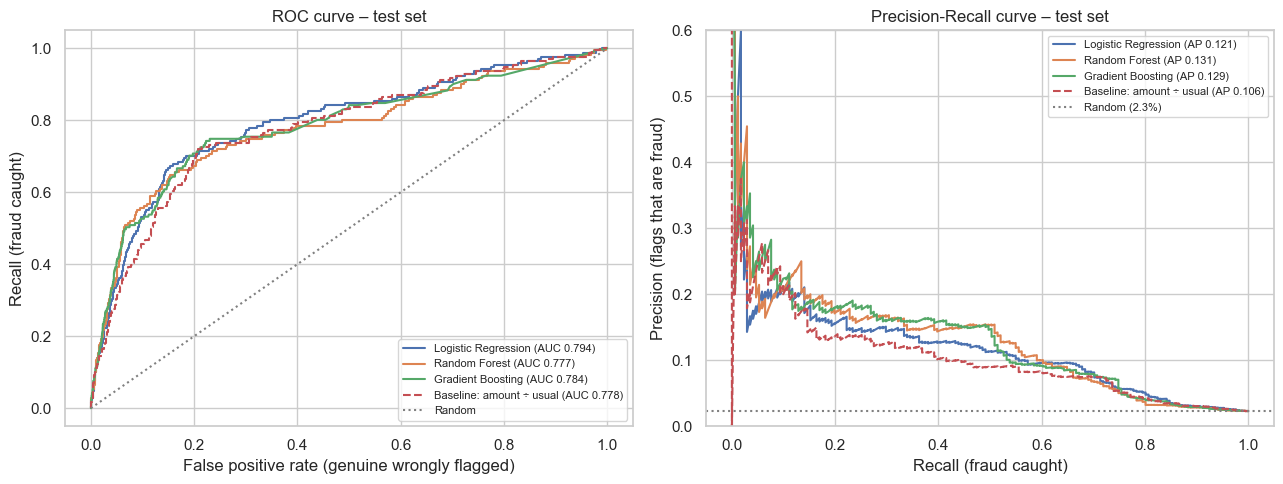

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
all_scores = {**test_scores, "Baseline: amount ÷ usual": test_ratio.values}

for name, s in all_scores.items():
    style = "--" if name.startswith("Baseline") else "-"
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, style, label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, style, label=f"{name} (AP {average_precision_score(y_test, s):.3f})")

axes[0].plot([0, 1], [0, 1], ":", color="grey", label="Random")
axes[0].set(xlabel="False positive rate (genuine wrongly flagged)",
            ylabel="Recall (fraud caught)", title="ROC curve – test set")
axes[1].axhline(y_test.mean(), linestyle=":", color="grey", label=f"Random ({y_test.mean():.1%})")
axes[1].set(xlabel="Recall (fraud caught)", ylabel="Precision (flags that are fraud)",
            title="Precision-Recall curve – test set", ylim=(0, 0.6))
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "model_01_roc_pr_curves.png", dpi=150)
plt.show()

**Result:** the three model curves are close together and above the baseline over most of the range. The precision-recall curve shows the core trade-off: to catch more fraud (moving right) we must accept lower precision (more false alarms). To catch ~70% of fraud, precision drops to around 6–8%.

### 2.11 Does the model still work on future months? (time-based check)

The random split mixes transactions from all months into both sets. In real life the model is trained on the **past** and used on the **future**. Fraud patterns can change over time, so we check this too:

- Train on transactions **before April 2026** (first 75%)
- Test on **April–August 2026** (last 25%)

If the scores hold up, the model is not just learning patterns that happen to exist in one period.

In [26]:
cutoff = df["Timestamp"].quantile(0.75)
past, future = df["Timestamp"] < cutoff, df["Timestamp"] >= cutoff
print(f"Train: before {cutoff.date()} ({past.sum():,} rows) | Test: from {cutoff.date()} ({future.sum():,} rows)\n")

time_rows = {}
for name, model in models.items():
    pipe = make_pipeline(clone(model)).fit(X[past], y[past])
    s = pipe.predict_proba(X[future])[:, 1]
    time_rows[name] = {"ROC-AUC": roc_auc_score(y[future], s),
                       "PR-AUC": average_precision_score(y[future], s)}
pd.DataFrame(time_rows).T.round(3)

Train: before 2026-04-01 (22,500 rows) | Test: from 2026-04-01 (7,500 rows)



,ROC-AUC,PR-AUC
Logistic Regression,0.780,0.096
Random Forest,0.795,0.123
Gradient Boosting,0.775,0.119


**Result:** on the later months the scores are similar to the random split (ROC-AUC ~0.78–0.80, PR-AUC ~0.10–0.12). The fraud patterns are **stable over time**, which supports using the model on future transactions. It should still be re-checked regularly in production, because fraudsters adapt.

### 2.12 What drives the predictions? (explainability)

Banks must be able to explain why a transaction was flagged. We look at this two ways.

**A. Logistic regression weights.** Each feature gets one weight. Positive = raises the fraud probability, negative = lowers it. Because the numeric features were scaled, their weights can be compared with each other.

**B. Permutation importance (for Gradient Boosting).** Tree models have no simple weights. Instead we take one feature, shuffle its values randomly in the test set, and see how much PR-AUC drops. If the score drops a lot, the model relied on that feature. If it doesn't drop, the feature wasn't useful.

*(The brief suggests SHAP for explainability. SHAP isn't installed here; permutation importance answers the same question – which features matter – and is built into scikit-learn. To add SHAP later: `pip install shap`.)*

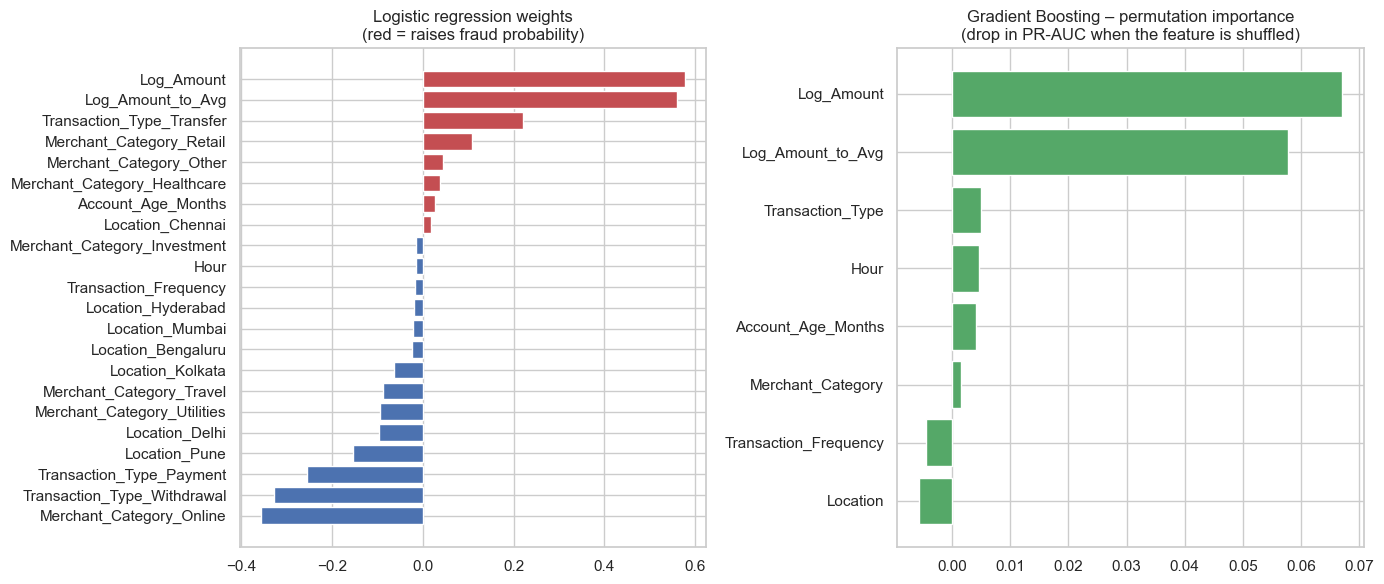

Log_Amount               0.0671
Log_Amount_to_Avg        0.0578
Transaction_Type         0.0050
Hour                     0.0047
Account_Age_Months       0.0041
Merchant_Category        0.0015
Transaction_Frequency   -0.0045
Location                -0.0057
dtype: float64

In [27]:
lr = fitted["Logistic Regression"]
lr_weights = pd.Series(lr.named_steps["model"].coef_[0],
                       index=lr.named_steps["prep"].get_feature_names_out())
lr_weights.index = lr_weights.index.str.replace("num__", "").str.replace("cat__", "")
lr_weights = lr_weights.sort_values()

perm = permutation_importance(fitted["Gradient Boosting"], X_test, y_test,
                              scoring="average_precision", n_repeats=10, random_state=42)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ["#C44E52" if w > 0 else "#4C72B0" for w in lr_weights]
axes[0].barh(lr_weights.index, lr_weights.values, color=colors)
axes[0].set_title("Logistic regression weights\n(red = raises fraud probability)")
axes[1].barh(perm_imp.index, perm_imp.values, color="#55A868")
axes[1].set_title("Gradient Boosting – permutation importance\n(drop in PR-AUC when the feature is shuffled)")
plt.tight_layout()
plt.savefig(RESULTS / "model_02_feature_importance.png", dpi=150)
plt.show()

perm_imp.sort_values(ascending=False).round(4)

**Result:** both methods agree, and they match the EDA:
1. **`Log_Amount`** and **`Log_Amount_to_Avg`** dominate – large transactions, and transactions far above the customer's usual amount, drive the fraud score.
2. **Transfers** raise the score; payments and withdrawals lower it.
3. Account age, hour, merchant, location and frequency add very little. Shuffling location or frequency even slightly *improves* the score, which means those features are basically noise.

This is good for governance: the model's logic is simple and makes business sense – "large, unusual transfers are risky" – so it can be explained to investigators, customers and regulators.

### 2.13 Choosing the model

| | Logistic Regression | Random Forest | Gradient Boosting |
|---|---|---|---|
| Ranking (ROC-AUC, PR-AUC) | Good | Good | Good |
| Fraud caught in top 5% | ~32% | ~33% | **~35%** |
| Probabilities trustworthy (Brier) | No (inflated) | No (inflated) | **Yes** |
| Explainability | **Best** | Medium | Medium |

**Choice: Gradient Boosting** as the main model, for two reasons:
1. It catches slightly more fraud in the top 5%.
2. Its probabilities are **well calibrated** (best Brier score). Step 4 uses probabilities to compare the ₹10,000 cost of missed fraud with the ₹500 cost of an investigation, so the probabilities need to mean what they say.

**Logistic Regression** is kept as a **challenger model**: almost as good, and the easiest to explain. In model governance, a simple challenger model is a useful check on the main one.

We save the test-set predictions to a CSV so Steps 3 and 4 (and the final report) can use them.

In [28]:
BEST_MODEL = "Gradient Boosting"
best_pipe = fitted[BEST_MODEL]
p_fraud_test = test_scores[BEST_MODEL]

predictions = pd.DataFrame({
    "Transaction_ID": df.loc[X_test.index, "Transaction_ID"],
    "Fraud_Flag": y_test,
    "P_Fraud_GB": p_fraud_test,
    "P_Fraud_LogReg": test_scores["Logistic Regression"],
})
predictions.to_csv(RESULTS / "m3_test_predictions.csv", index=False)
results.round(3).to_csv(RESULTS / "m3_model_comparison.csv")
print("Saved results/m3_test_predictions.csv and results/m3_model_comparison.csv")
predictions.head()

Saved results/m3_test_predictions.csv and results/m3_model_comparison.csv


,Transaction_ID,Fraud_Flag,P_Fraud_GB,P_Fraud_LogReg
4767,5004768,0,0.007193,0.247077
25530,5025531,0,0.036814,0.732435
15382,5015383,0,0.007970,0.113640
20446,5020447,0,0.007193,0.289774
12866,5012867,0,0.015447,0.465744


### 2.14 Summary of Step 2

- We trained **Logistic Regression, Random Forest and Gradient Boosting** using 8 features, with a stratified 75/25 train/test split and 5-fold cross-validation.
- All models perform similarly: **ROC-AUC ~0.78–0.80, PR-AUC ~0.12–0.13** (random = 0.023). They beat the simple amount ÷ usual rule on PR-AUC and fraud caught in the top 5%, though only modestly.
- Reviewing the **top 5% most suspicious transactions catches about a third of all fraud**, with about 1 in 6 flags being real fraud.
- Results hold on **later months** (time-based check), so the model generalises to future data.
- The key drivers are **transaction size and how unusual it is for the customer**, then **transfers**. The logic is simple and explainable.
- **Chosen model: Gradient Boosting** (best calibrated probabilities), with Logistic Regression as the explainable challenger.

**Honest limitation for the report:** the models are clearly useful but far from perfect – most fraud in this data doesn't look very different from genuine transactions on the features we have. Richer data (device history, IP address, velocity of recent transactions, merchant risk lists) would be needed for a big improvement. Model choice matters much less than data here.

**Next – Step 3:** can an Isolation Forest find fraud *without* using the labels at all?

---
# Step 3 – Unsupervised Detection with Isolation Forest

In Step 2 the model learned from **labelled** examples – we told it which past transactions were fraud. In real life labels are often missing or late: a fraud may only be reported weeks later, and **new kinds of fraud** have no past examples at all.

**Unsupervised** detection doesn't use the labels. It only asks: *which transactions look unusual compared with all the others?* The hope is that fraud tends to be unusual.

**Isolation Forest – the idea in plain words:**
- Imagine trying to isolate one transaction from all the others by asking random yes/no questions, like "is the amount above ₹20,000?" or "is the account younger than 2 years?"
- A **normal** transaction sits in a crowd of similar ones, so it takes many questions to separate it.
- An **unusual** transaction sits far from the crowd, so a few questions are enough.
- The forest repeats this with hundreds of random trees. Transactions that are isolated quickly, on average, get a high **anomaly score**.

What we will do:
1. Train an Isolation Forest **without** `Fraud_Flag`
2. Score the test set and compare with the supervised model from Step 2
3. Look at *what* the Isolation Forest flags, and why it differs
4. Check whether the two methods catch the same frauds or different ones

### 3.1 Choose the features

We use the same **numeric** features as Step 2, so the comparison is fair:
`Log_Amount`, `Log_Amount_to_Avg`, `Account_Age_Months`, `Transaction_Frequency`, `Hour`.

We leave out the category columns (type, merchant, city). Isolation Forest splits on numeric ranges, and one-hot 0/1 columns make poor splitting points for it. In Step 2 they added little anyway.

We **scale** the features with `StandardScaler` so each one has a similar range. The scaler is fitted on the training set only (no leakage).

In [29]:
from sklearn.ensemble import IsolationForest

IF_FEATURES = ["Log_Amount", "Log_Amount_to_Avg", "Account_Age_Months",
               "Transaction_Frequency", "Hour"]

if_scaler = StandardScaler().fit(X_train[IF_FEATURES])
X_train_if = if_scaler.transform(X_train[IF_FEATURES])
X_test_if = if_scaler.transform(X_test[IF_FEATURES])
print("Training rows:", X_train_if.shape[0], "| features:", X_train_if.shape[1])

Training rows: 22500 | features: 5


### 3.2 Train the Isolation Forest

Note that we call `.fit(X_train_if)` with **no `y_train`** – the model never sees the fraud labels.

Settings:
- `n_estimators=300` – the number of random trees. More trees give more stable scores.
- `contamination=0.05` – our guess at the share of unusual transactions. It doesn't change the scores, only where the model draws the line between "normal" and "anomaly". We choose 5% so the flags match the "top 5%" business metric from Step 2.
- `random_state=42` – reproducible results.

In [30]:
iso_forest = IsolationForest(n_estimators=300, contamination=0.05, random_state=42)
iso_forest.fit(X_train_if)        # no labels used

,n_estimators,300
,max_samples,'auto'
,contamination,0.05
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


### 3.3 Score the test set

- `score_samples()` returns a "normality" score: **lower = more unusual**. We flip the sign so that **higher = more unusual**, which matches the fraud probability (higher = more suspicious) and lets us reuse our `evaluate` function.
- `predict()` returns **-1 for anomalies** and **1 for normal**, using the 5% line.

Only now, *after* scoring, do we bring in the labels to check how well the anomalies match real fraud.

Flagged as anomalies: 400 of 7,500 (5.3%)
Frauds among them:    33 of 171 total frauds (19.3% caught)
Precision:            8.2% of anomalies are fraud


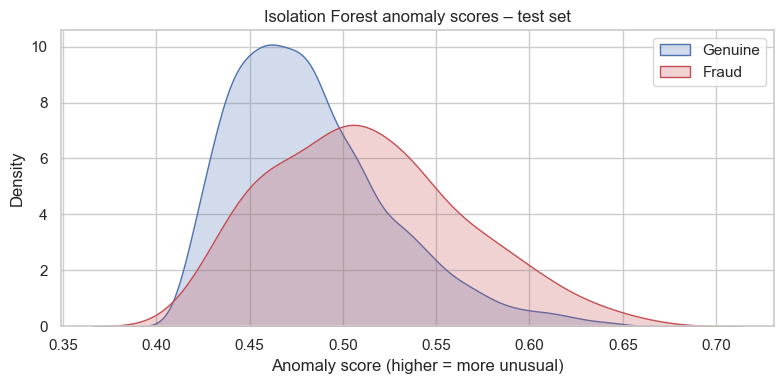

In [31]:
anomaly_score = -iso_forest.score_samples(X_test_if)
is_anomaly = iso_forest.predict(X_test_if) == -1

print(f"Flagged as anomalies: {is_anomaly.sum()} of {len(is_anomaly):,} ({is_anomaly.mean():.1%})")
print(f"Frauds among them:    {y_test[is_anomaly].sum()} of {y_test.sum()} total frauds "
      f"({y_test[is_anomaly].sum() / y_test.sum():.1%} caught)")
print(f"Precision:            {y_test[is_anomaly].mean():.1%} of anomalies are fraud")

fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(anomaly_score[y_test.values == 0], ax=ax, label="Genuine", fill=True, color="#4C72B0")
sns.kdeplot(anomaly_score[y_test.values == 1], ax=ax, label="Fraud", fill=True, color="#C44E52")
ax.set(xlabel="Anomaly score (higher = more unusual)", title="Isolation Forest anomaly scores – test set")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "iforest_01_score_distribution.png", dpi=150)
plt.show()

**Result:** the Isolation Forest flags about 400 transactions (5%) and only about 1 in 12 of them is fraud. It catches roughly 1 in 5 of all frauds.

In the chart, fraud transactions are shifted slightly to the right (more unusual), but the two curves **overlap heavily**. Being unusual and being fraud are related, but they are not the same thing.

### 3.4 Supervised vs unsupervised – head-to-head

We score the Isolation Forest with the same `evaluate` function as in Step 2 and put it next to the Gradient Boosting model and the simple rule.

In [32]:
comparison = pd.DataFrame({
    "Gradient Boosting (supervised)": evaluate(y_test, p_fraud_test),
    "Isolation Forest (unsupervised)": evaluate(y_test, anomaly_score),
    "Baseline: amount ÷ usual": baseline,
}).T.drop(columns="Brier")
comparison.loc["Random guess"] = [0.5, y_test.mean(), 0.05, y_test.mean()]
comparison.round(3)

,ROC-AUC,PR-AUC,Fraud caught in top 5%,Precision in top 5%
Gradient Boosting (supervised),0.784,0.129,0.351,0.160
Isolation Forest (unsupervised),0.676,0.054,0.170,0.077
Baseline: amount ÷ usual,0.778,0.106,0.275,0.125
Random guess,0.500,0.023,0.050,0.023


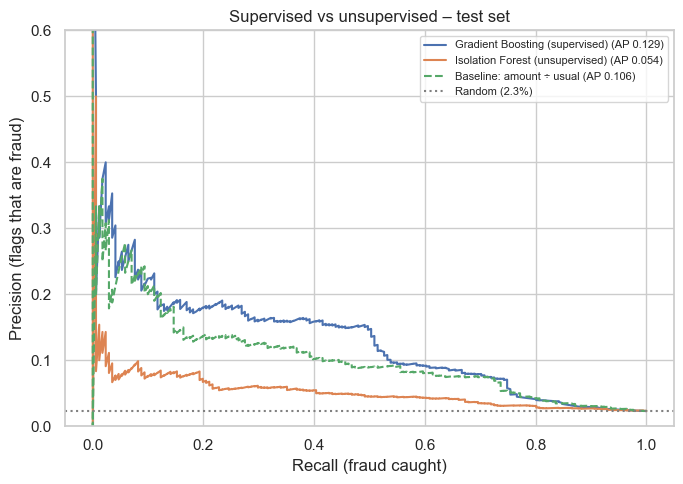

In [33]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, s, style in [("Gradient Boosting (supervised)", p_fraud_test, "-"),
                       ("Isolation Forest (unsupervised)", anomaly_score, "-"),
                       ("Baseline: amount ÷ usual", test_ratio.values, "--")]:
    prec, rec, _ = precision_recall_curve(y_test, s)
    ax.plot(rec, prec, style, label=f"{name} (AP {average_precision_score(y_test, s):.3f})")
ax.axhline(y_test.mean(), linestyle=":", color="grey", label=f"Random ({y_test.mean():.1%})")
ax.set(xlabel="Recall (fraud caught)", ylabel="Precision (flags that are fraud)",
       title="Supervised vs unsupervised – test set", ylim=(0, 0.6))
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "iforest_02_pr_comparison.png", dpi=150)
plt.show()

**Result:**

| | Supervised (GB) | Unsupervised (IF) |
|---|---|---|
| PR-AUC | ~0.13 | ~0.05 |
| Fraud caught in top 5% | ~35% | ~17% |

The Isolation Forest is **better than random** (PR-AUC ~0.05 vs 0.023), so "unusual" does carry some fraud signal. But it is clearly **weaker than the supervised model**, and even weaker than the simple amount ÷ usual rule. Learning from labelled examples is much more powerful when labels are available.

### 3.5 Why is the Isolation Forest weaker? What does it actually flag?

Isolation Forest looks for anything unusual **in any direction**. A transaction that is unusually *small*, or made at an unusual hour by a very old account, is just as "unusual" as one that is unusually *large*. But the EDA showed that fraud is about unusually **large** transactions.

We compare the transactions it flags with the fraud cases.

Median values:


,All test transactions,Flagged by Isolation Forest,Actual fraud
Amount,6525.82,2418.92,25765.96
Amount_to_Avg,1.20,0.39,4.67
Account_Age_Months,92.00,83.50,94.00


Share of IF anomalies where the amount is BELOW the customer's usual: 55%


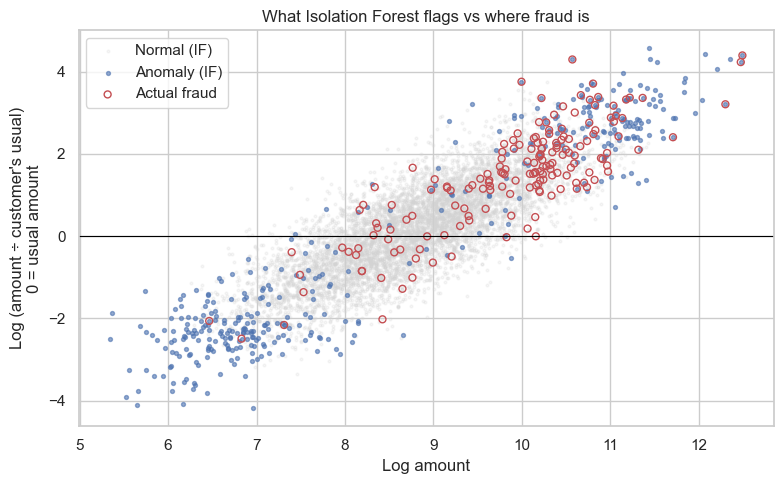

In [34]:
test_view = df.loc[X_test.index, ["Amount", "Historical_Avg_Transaction", "Account_Age_Months"]].copy()
test_view["Amount_to_Avg"] = test_view["Amount"] / test_view["Historical_Avg_Transaction"]
test_view["IF_anomaly"] = is_anomaly
test_view["Fraud"] = y_test.values

summary = pd.DataFrame({
    "All test transactions": test_view.median(numeric_only=True),
    "Flagged by Isolation Forest": test_view[test_view["IF_anomaly"]].median(numeric_only=True),
    "Actual fraud": test_view[test_view["Fraud"] == 1].median(numeric_only=True),
}).loc[["Amount", "Amount_to_Avg", "Account_Age_Months"]].round(2)
print("Median values:")
display(summary)

below_usual = (test_view.loc[test_view["IF_anomaly"], "Amount_to_Avg"] < 1).mean()
print(f"Share of IF anomalies where the amount is BELOW the customer's usual: {below_usual:.0%}")

fig, ax = plt.subplots(figsize=(8, 5))
normal = ~test_view["IF_anomaly"]
ax.scatter(X_test.loc[normal, "Log_Amount"], X_test.loc[normal, "Log_Amount_to_Avg"],
           s=4, alpha=0.2, color="lightgrey", label="Normal (IF)")
ax.scatter(X_test.loc[~normal, "Log_Amount"], X_test.loc[~normal, "Log_Amount_to_Avg"],
           s=8, alpha=0.6, color="#4C72B0", label="Anomaly (IF)")
fraud = test_view["Fraud"] == 1
ax.scatter(X_test.loc[fraud, "Log_Amount"], X_test.loc[fraud, "Log_Amount_to_Avg"],
           s=25, facecolors="none", edgecolors="#C44E52", label="Actual fraud")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="Log amount", ylabel="Log (amount ÷ customer's usual)\n0 = usual amount",
       title="What Isolation Forest flags vs where fraud is")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "iforest_03_what_it_flags.png", dpi=150)
plt.show()

**Result:** this explains the gap.
- The **median amount** of IF-flagged transactions (~₹2,400) is **lower** than the median of all transactions (~₹6,500), while the median fraud is ~₹26,000.
- About **55% of IF anomalies are *below* the customer's usual amount** – unusually small transactions, which are rarely fraud here.
- In the scatter plot, the blue anomalies sit at **both edges** of the cloud (top-right *and* bottom-left), while the red fraud circles are mostly in the **upper-right** (large and above usual).

So the Isolation Forest is doing its job – finding unusual transactions – but half of what is unusual here is harmless. The supervised model knows which direction is risky because it learned from the labels.

### 3.6 Do the two methods catch the same frauds?

If the Isolation Forest caught *different* frauds from the supervised model, it could be a useful second line of defence even though it is weaker overall. We take the top 5% (375 transactions) from each method and compare which frauds each one finds.

,Frauds (of 171)
Caught by both,21
Only Gradient Boosting,39
Only Isolation Forest,8
Caught by neither,103


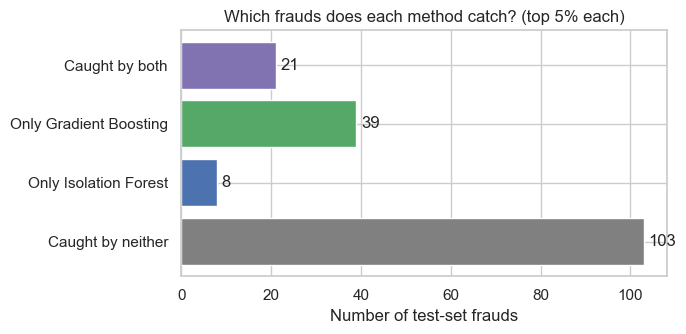

In [35]:
n_top = int(len(y_test) * 0.05)
fraud_positions = set(np.where(y_test.values == 1)[0])
caught_gb = fraud_positions & set(np.argsort(-p_fraud_test)[:n_top])
caught_if = fraud_positions & set(np.argsort(-anomaly_score)[:n_top])

overlap = pd.Series({
    "Caught by both": len(caught_gb & caught_if),
    "Only Gradient Boosting": len(caught_gb - caught_if),
    "Only Isolation Forest": len(caught_if - caught_gb),
    "Caught by neither": len(fraud_positions - caught_gb - caught_if),
}, name="Frauds (of 171)")
display(overlap.to_frame())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(overlap.index[::-1], overlap.values[::-1],
        color=["grey", "#4C72B0", "#55A868", "#8172B2"])
for i, v in enumerate(overlap.values[::-1]):
    ax.text(v + 1, i, str(v), va="center")
ax.set(xlabel="Number of test-set frauds", title="Which frauds does each method catch? (top 5% each)")
plt.tight_layout()
plt.savefig(RESULTS / "iforest_04_overlap.png", dpi=150)
plt.show()

**Result:** most frauds the Isolation Forest catches are **also caught** by the supervised model. Only a handful (~8) are found by the Isolation Forest alone, while the supervised model finds ~39 that the Isolation Forest misses. About 100 frauds are caught by neither – they look like normal transactions on the features we have.

### 3.7 Does combining them help?

One last check: we blend the two rankings into one score – 90% supervised, 10% unsupervised – and see if it beats the supervised model alone.

We blend **ranks** rather than raw scores (`rankdata` turns scores into positions 1, 2, 3, …), because a probability and an anomaly score are on different scales.

In [36]:
from scipy.stats import rankdata

blend_rows = {"Gradient Boosting alone": evaluate(y_test, p_fraud_test)}
for w in [0.9, 0.7, 0.5]:
    blended = w * rankdata(p_fraud_test) + (1 - w) * rankdata(anomaly_score)
    blend_rows[f"Blend {round(w*100)}% GB / {round((1-w)*100)}% IF"] = evaluate(y_test, blended)
pd.DataFrame(blend_rows).T.drop(columns="Brier").round(3)

,ROC-AUC,PR-AUC,Fraud caught in top 5%,Precision in top 5%
Gradient Boosting alone,0.784,0.129,0.351,0.160
Blend 90% GB / 10% IF,0.784,0.136,0.368,0.168
Blend 70% GB / 30% IF,0.777,0.130,0.339,0.155
Blend 50% GB / 50% IF,0.761,0.120,0.327,0.149


**Result:** a small share of Isolation Forest (10%) adds about 3 extra frauds caught in the top 5% – too small a gain to rely on, since it is within normal random variation. Giving it more weight (30% or 50%) makes the results **no better, or worse**. So on this data the Isolation Forest is **not worth adding to the main score**.

### 3.8 Summary of Step 3

| | Supervised (Gradient Boosting) | Unsupervised (Isolation Forest) |
|---|---|---|
| Uses fraud labels? | Yes | No |
| PR-AUC (test) | ~0.13 | ~0.05 |
| Fraud caught in top 5% | ~35% | ~17% |
| What it finds | Transactions that **look like past fraud** | Transactions that are **unusual in any direction** |
| Main weakness | Can't recognise new fraud types it has never seen | Flags many harmless unusual transactions (e.g. very small ones) |

**Conclusions**
1. When labels are available, **supervised learning is clearly better** – about twice as much fraud caught for the same investigation effort.
2. Isolation Forest is **better than random** but weaker even than the simple amount rule, because about half of what it calls "unusual" is unusually *small* – harmless.
3. It catches almost no frauds that the supervised model misses, and blending them gives no reliable gain.

**Recommendation for NovaFin:** use the **supervised model as the main fraud score**. Keep the Isolation Forest as a **monitoring tool**, not an alerting tool:
- to spot **new fraud patterns** the supervised model hasn't seen yet (e.g. a sudden cluster of anomalies from one city),
- to detect **data drift** – if the share of anomalies suddenly changes, the customer base or the fraud has changed, and the supervised model should be retrained,
- for **new products** where no fraud labels exist yet.

**Next – Step 4:** choose the probability cut-off that minimises the total cost of missed fraud (₹10,000 each) and investigations (₹500 each).

---
# Step 4 – Cost-Based Threshold

The model gives every transaction a fraud probability. To act on it, NovaFin needs a **threshold** (cut-off): investigate every transaction above it, let the rest through.

Each choice has a cost:

| Outcome | What happened | Cost (from the brief) |
|---|---|---|
| **False negative** (missed fraud) | Fraud below the threshold, not investigated | **₹10,000** lost |
| **False positive** (false alarm) | Genuine transaction investigated for nothing | **₹500** investigation cost |
| True positive (fraud caught) | Fraud investigated and stopped | ₹0 (we assume the loss is prevented) |
| True negative | Genuine transaction let through | ₹0 |

**Total cost = (missed frauds × ₹10,000) + (false alarms × ₹500)**

- A **high** threshold → few investigations, but many missed frauds (expensive).
- A **low** threshold → catches more fraud, but many false alarms.

The goal is the threshold in between that makes the **total cost as small as possible**.

**Assumptions** (to state in the report): investigating a fraud stops the whole loss; the investigation cost of a *true* fraud is ignored, as in the brief (we test this in 4.7); investigation capacity is unlimited.

### 4.1 The cost function

A small function that, for a given threshold, counts the four outcomes and adds up the cost. `scores >= threshold` gives True for every transaction we would investigate.

In [37]:
COST_MISSED_FRAUD = 10_000   # ₹ per false negative
COST_FALSE_ALARM = 500       # ₹ per false positive

def cost_at_threshold(y_true, scores, threshold,
                      cost_fn=COST_MISSED_FRAUD, cost_fp=COST_FALSE_ALARM, cost_tp=0):
    y_true = np.asarray(y_true)
    flagged = scores >= threshold
    tp = int(( flagged & (y_true == 1)).sum())   # fraud caught
    fp = int(( flagged & (y_true == 0)).sum())   # false alarm
    fn = int((~flagged & (y_true == 1)).sum())   # fraud missed
    return {
        "Threshold": threshold,
        "Investigated": int(flagged.sum()),
        "Fraud caught": tp,
        "False alarms": fp,
        "Fraud missed": fn,
        "Recall": tp / max(tp + fn, 1),
        "Precision": tp / max(tp + fp, 1),
        "Cost of missed fraud (₹)": fn * cost_fn,
        "Cost of investigations (₹)": fp * cost_fp + tp * cost_tp,
        "Total cost (₹)": fn * cost_fn + fp * cost_fp + tp * cost_tp,
    }

### 4.2 The theory: where should the threshold be?

For one transaction with fraud probability **p**:
- If we **don't** investigate, the expected loss is **p × ₹10,000** (the chance it's fraud times the loss).
- If we **do** investigate, the expected cost is **(1 − p) × ₹500** (the chance it's genuine times the wasted investigation).

Investigating is worth it when p × 10,000 > (1 − p) × 500. Solving for p:

**p > 500 / (500 + 10,000) = 0.0476, i.e. about 4.8%**

So we should investigate any transaction with **more than a ~4.8% chance of fraud** – far below the default cut-off of 50%. Because a miss costs 20× more than a false alarm, it's worth checking about 20 genuine transactions to find one fraud.

This only works if the probabilities are **calibrated** (a 5% prediction really means about 5%). That's why we chose Gradient Boosting in Step 2, which had the best Brier score.

In [38]:
theory_threshold = COST_FALSE_ALARM / (COST_FALSE_ALARM + COST_MISSED_FRAUD)
print(f"Theoretical cost-optimal threshold: {theory_threshold:.4f} ({theory_threshold:.2%})")

Theoretical cost-optimal threshold: 0.0476 (4.76%)


### 4.3 Find the threshold from data – without touching the test set

We also find the best threshold **empirically**: try many thresholds and pick the cheapest.

**Important – avoid leakage:** if we picked the threshold on the test set and then reported the cost on the same test set, the result would be too optimistic (we'd be tuning to the exam). So we choose the threshold on the **training set** and only then check it on the test set.

But the training set was used to train the model, so the model's predictions on it are too good. The fix is **out-of-fold predictions** with `cross_val_predict`: the training data is split into 5 folds, and each fold is predicted by a model trained on the *other* 4. Every training transaction gets a prediction from a model that never saw it.

We then try thresholds from 0.5% to 50% in steps of 0.25%.

In [39]:
from sklearn.model_selection import cross_val_predict

oof_scores = cross_val_predict(make_pipeline(clone(models[BEST_MODEL])), X_train, y_train,
                               cv=cv, method="predict_proba")[:, 1]

thresholds = np.round(np.arange(0.005, 0.5, 0.0025), 4)
train_curve = pd.DataFrame([cost_at_threshold(y_train, oof_scores, t) for t in thresholds])
best_row = train_curve.loc[train_curve["Total cost (₹)"].idxmin()]
chosen_threshold = best_row["Threshold"]

print(f"Cost-optimal threshold on training data (out-of-fold): {chosen_threshold:.4f}")
print(f"Theoretical threshold:                                  {theory_threshold:.4f}")

Cost-optimal threshold on training data (out-of-fold): 0.0475
Theoretical threshold:                                  0.0476


**Result:** the threshold found from the data (**~0.0475**) matches the theoretical value (**0.0476**) almost exactly. This is a strong check that the Gradient Boosting probabilities are well calibrated – the theory and the data agree.

### 4.4 The cost curve

We plot the total cost at every threshold, split into its two parts:
- **Red – cost of missed fraud:** rises as the threshold goes up (we investigate less, so we miss more fraud)
- **Blue – cost of investigations:** falls as the threshold goes up (fewer false alarms)
- **Black – total:** the sum. Its lowest point is the best threshold.

We plot the curve for both the training data (used to choose) and the test data (used to check).

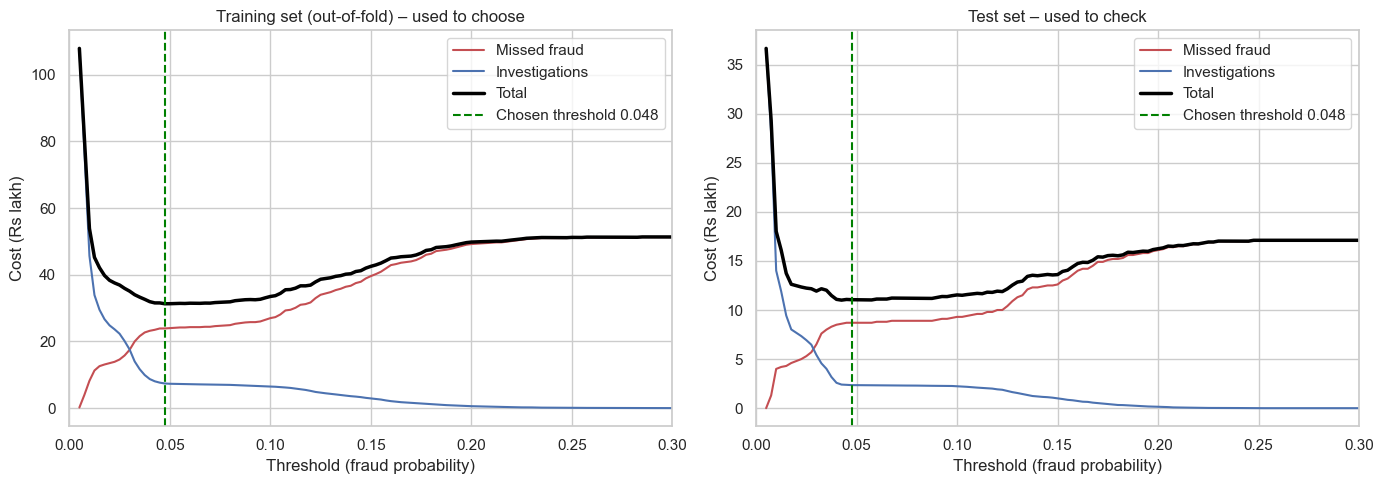

In [40]:
test_curve = pd.DataFrame([cost_at_threshold(y_test, p_fraud_test, t) for t in thresholds])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, curve, title in [(axes[0], train_curve, "Training set (out-of-fold) – used to choose"),
                         (axes[1], test_curve, "Test set – used to check")]:
    ax.plot(curve["Threshold"], curve["Cost of missed fraud (₹)"] / 1e5, color="#C44E52", label="Missed fraud")
    ax.plot(curve["Threshold"], curve["Cost of investigations (₹)"] / 1e5, color="#4C72B0", label="Investigations")
    ax.plot(curve["Threshold"], curve["Total cost (₹)"] / 1e5, color="black", linewidth=2.5, label="Total")
    ax.axvline(chosen_threshold, color="green", linestyle="--", label=f"Chosen threshold {chosen_threshold:.3f}")
    ax.set(xlabel="Threshold (fraud probability)", ylabel="Cost (Rs lakh)", title=title, xlim=(0, 0.3))
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "cost_01_cost_curve.png", dpi=150)
plt.show()

**Result:** the total cost (black) falls steeply as the threshold rises from 0, reaches its lowest point near **0.05**, and then climbs as more fraud is missed. The curve looks the same shape on the training and test sets, so the chosen threshold carries over to new data.

To the right of ~0.2 the total cost is almost flat at its maximum: the model almost never gives probabilities that high, so nothing gets flagged.

### 4.5 Compare policies on the test set

Now the business comparison. On the 7,500 test transactions (171 frauds), what would each policy cost NovaFin?

| Policy | Meaning |
|---|---|
| Do nothing | Investigate nothing – every fraud is lost |
| Investigate everything | Check all 7,500 transactions |
| Default threshold 0.5 | The standard ML cut-off, not adjusted for costs |
| Simple rule: > 3× usual amount | The baseline rule from Step 2 |
| **Cost-optimal threshold** | The threshold chosen in 4.3 |

In [41]:
y_arr = y_test.values
policies = {
    "Do nothing": cost_at_threshold(y_arr, p_fraud_test, np.inf),
    "Investigate everything": cost_at_threshold(y_arr, p_fraud_test, -np.inf),
    "Default threshold 0.5": cost_at_threshold(y_arr, p_fraud_test, 0.5),
    "Simple rule: > 3x usual amount": cost_at_threshold(y_arr, test_ratio.values, 3.0),
    "Cost-optimal threshold": cost_at_threshold(y_arr, p_fraud_test, chosen_threshold),
}
policy_table = pd.DataFrame(policies).T.drop(columns="Threshold")
do_nothing = policy_table.loc["Do nothing", "Total cost (₹)"]
policy_table["Saving vs do nothing (₹)"] = do_nothing - policy_table["Total cost (₹)"]
policy_table["Saving %"] = policy_table["Saving vs do nothing (₹)"] / do_nothing

show = policy_table.copy()
for col in ["Investigated", "Fraud caught", "False alarms", "Fraud missed"]:
    show[col] = show[col].astype(int)
for col in ["Recall", "Precision", "Saving %"]:
    show[col] = (show[col].astype(float) * 100).round(1).astype(str) + "%"
for col in [c for c in show.columns if "₹" in c]:
    show[col] = show[col].astype(float).map("{:,.0f}".format)
show

,Investigated,Fraud caught,False alarms,Fraud missed,Recall,Precision,Cost of missed fraud (₹),Cost of investigations (₹),Total cost (₹),Saving vs do nothing (₹),Saving %
Do nothing,0,0,0,171,0.0%,0.0%,"1,710,000",0,"1,710,000",0,0.0%
Investigate everything,7500,171,7329,0,100.0%,2.3%,0,"3,664,500","3,664,500","-1,954,500",-114.3%
Default threshold 0.5,0,0,0,171,0.0%,0.0%,"1,710,000",0,"1,710,000",0,0.0%
Simple rule: > 3x usual amount,1666,123,1543,48,71.9%,7.4%,"480,000","771,500","1,251,500","458,500",26.8%
Cost-optimal threshold,554,84,470,87,49.1%,15.2%,"870,000","235,000","1,105,000","605,000",35.4%


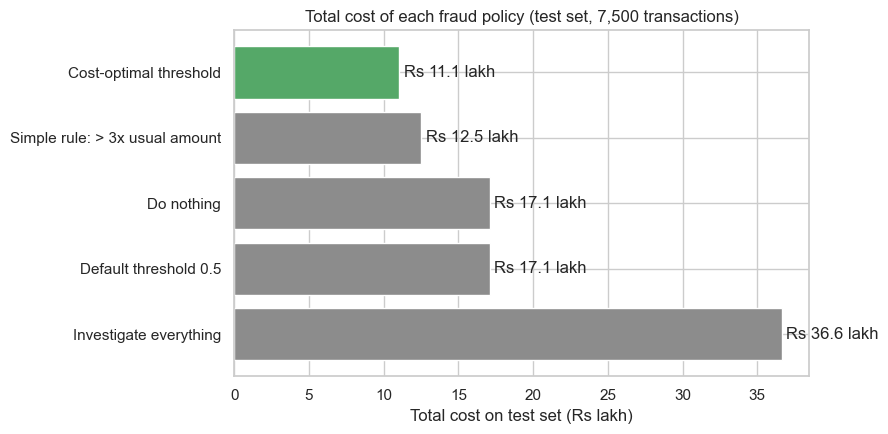

In [42]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = policy_table["Total cost (₹)"].astype(float).sort_values()
colors = ["#55A868" if n == "Cost-optimal threshold" else "#8C8C8C" for n in order.index]
ax.barh(order.index, order.values / 1e5, color=colors)
for i, v in enumerate(order.values):
    ax.text(v / 1e5 + 0.3, i, f"Rs {v / 1e5:.1f} lakh", va="center")
ax.set(xlabel="Total cost on test set (Rs lakh)", title="Total cost of each fraud policy (test set, 7,500 transactions)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(RESULTS / "cost_02_policy_comparison.png", dpi=150)
plt.show()

**Result:**
- **Do nothing** costs **₹17.1 lakh** (171 frauds × ₹10,000).
- The **default 0.5 threshold** costs exactly the same – the model never gives a probability above 0.5, so it flags nothing. *This is why the default cut-off is wrong for fraud.*
- **Investigating everything** is the most expensive (~₹36.6 lakh) – the false alarms cost more than the fraud.
- The **simple 3× rule** costs ~₹12.5 lakh (saves ~27%).
- The **cost-optimal threshold** costs **~₹11.1 lakh – a saving of ~₹6 lakh (~35%)** compared with doing nothing, and ~₹1.5 lakh less than the simple rule. It investigates ~7% of transactions and catches about half of all fraud.

### 4.6 Confusion matrix at the chosen threshold

A **confusion matrix** shows the four outcomes in a 2×2 grid: rows are what actually happened, columns are what the model decided. It is the clearest way to show investigators what to expect.

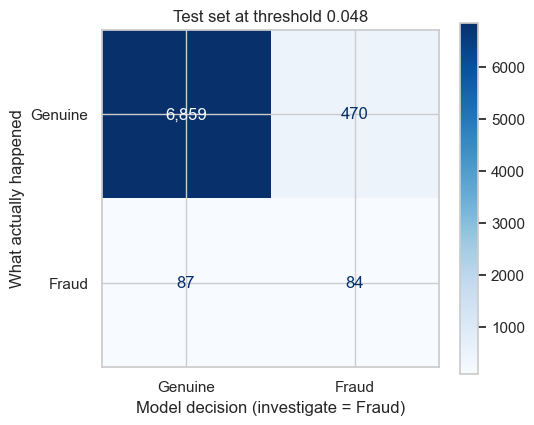

Investigations: 554 (7.4% of transactions)
  of which real fraud: 84 -> about 1 in 7 investigations finds fraud
Frauds missed: 87 of 171


In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

decision = (p_fraud_test >= chosen_threshold).astype(int)
cm = confusion_matrix(y_test, decision)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Genuine", "Fraud"]).plot(ax=ax, cmap="Blues", values_format=",")
ax.set(xlabel="Model decision (investigate = Fraud)", ylabel="What actually happened",
       title=f"Test set at threshold {chosen_threshold:.3f}")
plt.tight_layout()
plt.savefig(RESULTS / "cost_03_confusion_matrix.png", dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Investigations: {tp + fp:,} ({(tp + fp) / len(y_test):.1%} of transactions)")
print(f"  of which real fraud: {tp} -> about 1 in {round((tp + fp) / tp)} investigations finds fraud")
print(f"Frauds missed: {fn} of {tp + fn}")

**Result:** at the chosen threshold, investigators check about **550 of 7,500 transactions (~7%)**. About **1 in 7** of these investigations finds real fraud. About half of all fraud is still missed, because – as Step 2 showed – much of it looks like normal transactions on the features available.

### 4.7 Sensitivity analysis – what if the costs are different?

The ₹10,000 and ₹500 figures are assumptions. Management will ask: *"What if a missed fraud really costs ₹20,000? What if investigations cost more?"* We re-run the threshold search for different cost combinations (always choosing on the training set and reporting on the test set).

We also test the case where **every** investigation costs ₹500, including those that do find fraud.

The theoretical threshold for any costs is **investigation cost ÷ (investigation cost + missed-fraud cost)**.

In [44]:
sens_rows = []
for cost_fn in [5_000, 10_000, 20_000]:
    for cost_fp in [250, 500, 1_000]:
        curve = [cost_at_threshold(y_train, oof_scores, t, cost_fn, cost_fp)["Total cost (₹)"] for t in thresholds]
        t_best = thresholds[int(np.argmin(curve))]
        res = cost_at_threshold(y_arr, p_fraud_test, t_best, cost_fn, cost_fp)
        nothing = y_arr.sum() * cost_fn
        sens_rows.append({
            "Missed fraud cost (₹)": cost_fn, "Investigation cost (₹)": cost_fp,
            "Theory threshold": round(cost_fp / (cost_fp + cost_fn), 4),
            "Chosen threshold": t_best,
            "Investigated": res["Investigated"], "Recall": round(res["Recall"], 3),
            "Test cost (₹)": res["Total cost (₹)"],
            "Saving vs do nothing": f"{(nothing - res['Total cost (₹)']) / nothing:.0%}",
        })

curve = [cost_at_threshold(y_train, oof_scores, t, cost_tp=COST_FALSE_ALARM)["Total cost (₹)"] for t in thresholds]
t_best = thresholds[int(np.argmin(curve))]
res = cost_at_threshold(y_arr, p_fraud_test, t_best, cost_tp=COST_FALSE_ALARM)
sens_rows.append({
    "Missed fraud cost (₹)": "10,000 (+₹500 on caught fraud)", "Investigation cost (₹)": 500,
    "Theory threshold": round(500 / 10_000, 4), "Chosen threshold": t_best,
    "Investigated": res["Investigated"], "Recall": round(res["Recall"], 3),
    "Test cost (₹)": res["Total cost (₹)"],
    "Saving vs do nothing": f"{(y_arr.sum() * 10_000 - res['Total cost (₹)']) / (y_arr.sum() * 10_000):.0%}",
})

sensitivity = pd.DataFrame(sens_rows)
sensitivity.to_csv(RESULTS / "m3_cost_sensitivity.csv", index=False)
sensitivity

,Missed fraud cost (₹),Investigation cost (₹),Theory threshold,Chosen threshold,Investigated,Recall,Test cost (₹),Saving vs do nothing
0,5000,250,0.0476,0.0475,554,0.491,552500,35%
1,5000,500,0.0909,0.0650,546,0.485,671500,21%
2,5000,1000,0.1667,0.1700,126,0.129,849000,1%
3,10000,250,0.0244,0.0225,1589,0.708,867000,49%
4,10000,500,0.0476,0.0475,554,0.491,1105000,35%
5,10000,1000,0.0909,0.0650,546,0.485,1343000,21%
6,20000,250,0.0123,0.0100,2933,0.766,1500500,56%
7,20000,500,0.0244,0.0225,1589,0.708,1734000,49%
8,20000,1000,0.0476,0.0475,554,0.491,2210000,35%
9,"10,000 (+₹500 on caught fraud)",500,0.0500,0.0475,554,0.491,1147000,33%


**Result:**
- The best threshold **moves with the cost ratio**, as the theory predicts: when missed fraud is more expensive relative to investigations, the threshold drops and more transactions are investigated; when investigations are expensive, it rises.
- In every scenario the model-based policy **saves money** compared with doing nothing – a lot when missed fraud is expensive (up to ~56%), and almost nothing when an investigation costs a fifth of a missed fraud (₹1,000 vs ₹5,000), because then it is rarely worth investigating at all.
- Counting ₹500 for investigations that do find fraud barely changes anything – the threshold stays the same and cost rises only slightly.

Because the model's probabilities come in steps (it's built from small trees), a few nearby thresholds give the same result – that's why some rows share the same chosen threshold.

**Business message:** the threshold is a **business setting, not a fixed model property**. Finance and fraud teams should review it whenever loss or investigation costs change.

### 4.8 What does this mean at NovaFin's scale? (illustrative)

The test set is 7,500 transactions. To make the result meaningful to the Board we express it **per 10,000 transactions**, and then for an **assumed** volume.

The brief says NovaFin processes "thousands of transactions every day". We assume **5,000 transactions per day** as an illustration – replace this with the real figure if known.

In [45]:
TX_PER_DAY = 5_000   # assumption – "thousands of transactions every day"
best_policy = policy_table.loc["Cost-optimal threshold"]
per_tx = lambda v: float(v) / len(y_test)

saving_per_10k = per_tx(best_policy["Saving vs do nothing (₹)"]) * 10_000
annual_tx = TX_PER_DAY * 365
scale = pd.Series({
    "Saving per 10,000 transactions (₹)": saving_per_10k,
    "Investigations per day": per_tx(best_policy["Investigated"]) * TX_PER_DAY,
    "Frauds caught per day": per_tx(best_policy["Fraud caught"]) * TX_PER_DAY,
    "Annual fraud loss if no model (₹ crore)": per_tx(do_nothing) * annual_tx / 1e7,
    "Annual cost with model (₹ crore)": per_tx(best_policy["Total cost (₹)"]) * annual_tx / 1e7,
    "Annual saving (₹ crore)": per_tx(best_policy["Saving vs do nothing (₹)"]) * annual_tx / 1e7,
})
scale.round(1).to_frame("Value")

,Value
"Saving per 10,000 transactions (₹)",806666.7
Investigations per day,369.3
Frauds caught per day,56.0
Annual fraud loss if no model (₹ crore),41.6
Annual cost with model (₹ crore),26.9
Annual saving (₹ crore),14.7


**Result (illustrative, at 5,000 transactions a day):**
- The cost-optimal policy saves about **₹8 lakh per 10,000 transactions**.
- At 5,000 transactions a day that is roughly **₹15 crore a year** saved, against about ₹42 crore of annual fraud loss with no model.
- It needs about **370 investigations a day**. NovaFin must check it has this investigation capacity – if not, the threshold must be raised, which costs more in missed fraud. (A capacity-limited version would rank transactions and investigate only the top N per day.)

### 4.9 Save results

In [46]:
policy_table.to_csv(RESULTS / "m3_policy_comparison.csv")
train_curve.to_csv(RESULTS / "m3_cost_curve_train.csv", index=False)
print("Saved: m3_policy_comparison.csv, m3_cost_curve_train.csv, m3_cost_sensitivity.csv")

Saved: m3_policy_comparison.csv, m3_cost_curve_train.csv, m3_cost_sensitivity.csv


---
# Module 3 – Conclusions for the Board

**Question:** how can NovaFin identify suspicious transactions while minimising unnecessary investigation?

**1. Where fraud is (EDA)**
Fraud is 2.28% of transactions. It is driven by **unusually large transactions compared with the customer's normal spending** (median fraud ≈ 5× the customer's usual amount) and is somewhat more common in **transfers**. Merchant, city, time of day and frequency matter very little.

**2. Supervised model (recommended)**
Gradient Boosting, with Logistic Regression as the explainable challenger. ROC-AUC ~0.78, PR-AUC ~0.13 (random = 0.02). The patterns hold on later months. Its probabilities are well calibrated.

**3. Unsupervised model (monitoring only)**
Isolation Forest catches about half as much fraud for the same effort, because many "unusual" transactions are unusually *small* and harmless. Recommended for spotting new fraud patterns and data drift, not for alerts.

**4. Decision rule**
**Investigate any transaction with a predicted fraud probability above ~4.8%** (= ₹500 ÷ (₹500 + ₹10,000)). This is far below the default 50% cut-off, which would flag nothing.
- Investigates ~7% of transactions; catches ~half of all fraud; ~1 in 7 investigations finds fraud
- **Cuts total fraud-related cost by ~35%** vs no model, and beats a simple amount rule
- Illustratively ~₹15 crore a year at 5,000 transactions a day

**Risks & limitations**
- **Data:** the features separate fraud only moderately; about half of fraud still goes undetected. Adding device history, IP/geo-location changes, recent-transaction velocity and merchant risk lists is the biggest opportunity.
- **Synthetic data:** results must be re-validated on real NovaFin data.
- **Cost assumptions:** ₹10,000 / ₹500 are estimates; the threshold must be updated when they change (see sensitivity analysis).
- **Capacity:** ~370 investigations/day at the assumed volume – the fraud team must be sized for it.
- **Model drift:** fraudsters adapt. Monitor performance monthly, use the Isolation Forest to watch for new patterns, and retrain regularly.
- **Governance:** the main drivers (amount, unusualness, transfers) are intuitive and explainable to customers and regulators; the Logistic Regression challenger provides an independent check.

**Link to capital allocation (Module 11):** fraud controls reduce the expected loss on **digital banking** and transaction-heavy businesses. A working fraud model with a cost-based threshold makes growth in digital banking safer, which supports allocating capital there – together with investment in fraud-team capacity and better data.